In [48]:
pip install torch torchvision matplotlib

Note: you may need to restart the kernel to use updated packages.


These libraries give us the tools to create the neural network, load the MNIST data, train the model, and display images and graphs.

In [49]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [50]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

In [61]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 60000
Testing images: 10000


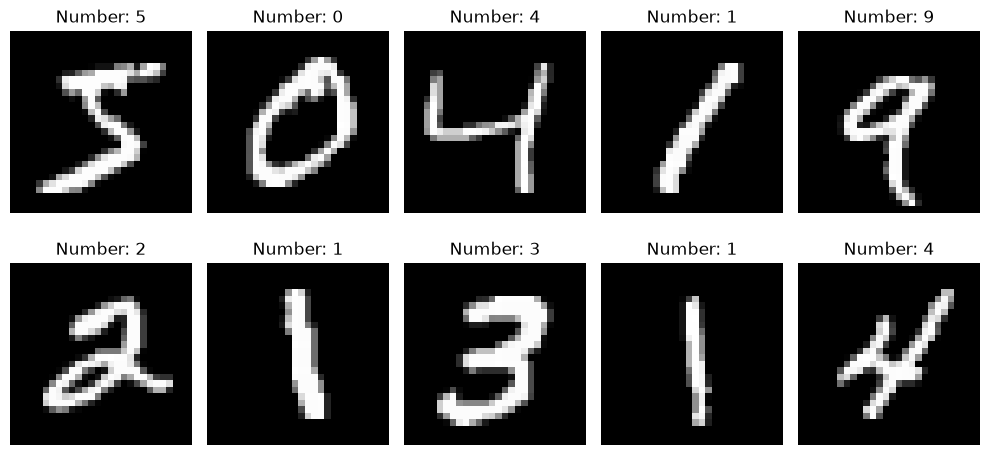

In [52]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Number: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [62]:
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

Creating our first nueral network. Model A

In [54]:
class MNISTClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = self.pool(x)

        x = F.relu(self.conv2(x))
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))

        return self.fc2(x)


model_a = MNISTClassifier()

print(model_a)

MNISTClassifier(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [55]:
# Move model to CPU or GPU
model_a = model_a.to(device)

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model_a.parameters(),
    lr=0.001
)

# Number of training rounds
epochs = 5

print("Model A is ready for training!")

Model A is ready for training!


Training the model A

In [56]:
for epoch in range(epochs):

    model_a.train()

    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model_a(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Clear old gradients
        optimizer.zero_grad()

        # Calculate gradients
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("Training completed!")

Epoch 1/5, Loss: 0.2351
Epoch 2/5, Loss: 0.0622
Epoch 3/5, Loss: 0.0438
Epoch 4/5, Loss: 0.0326
Epoch 5/5, Loss: 0.0276
Training completed!


In [57]:
model_a.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model_a(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

accuracy = 100 * correct / total

print("Model A accuracy:", accuracy, "%")

Model A accuracy: 99.02 %


In [58]:
torch.manual_seed(42)

model_b = MNISTClassifier()

optimizer_b = optim.Adam(
    model_b.parameters(),
    lr=0.001
)

In [63]:
def fgsm_attack(model, images, labels, epsilon):

    images = images.detach().clone()
    images.requires_grad = True

    outputs = model(images)

    loss = F.cross_entropy(outputs, labels)

    gradients = torch.autograd.grad(loss, images)[0]

    adversarial_images = (
        images + epsilon * gradients.sign()
    )

    adversarial_images = torch.clamp(
        adversarial_images, 0, 1
    )

    return adversarial_images.detach()

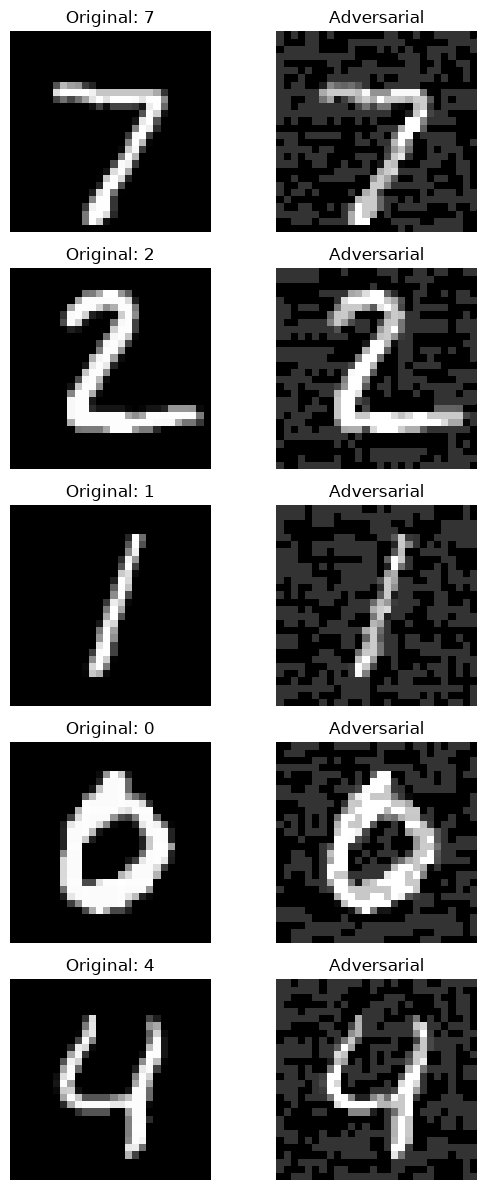

In [28]:
import matplotlib.pyplot as plt

# Select a batch of test images
images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

# Choose the perturbation strength
epsilon = 0.2

# Generate adversarial images using Model A
model_a.eval()
adv_images = fgsm_attack(model_a, images, labels, epsilon)

# Display the first 5 images
fig, axes = plt.subplots(5, 2, figsize=(6, 12))

for i in range(5):
    # Original image
    axes[i, 0].imshow(
        images[i].detach().cpu().squeeze(),
        cmap="gray"
    )
    axes[i, 0].set_title("Original: " + str(labels[i].item()))
    axes[i, 0].axis("off")

    # Adversarial image
    axes[i, 1].imshow(
        adv_images[i].detach().cpu().squeeze(),
        cmap="gray"
    )
    axes[i, 1].set_title("Adversarial")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

PART 2

In [26]:
epsilons = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

In [29]:
import torch

# Different epsilon values to test
epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35]

error_rates = []

model_a.eval()

for eps in epsilons:

    correct = 0
    total = 0

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Create adversarial images
        adv_images = fgsm_attack(
            model_a, images, labels, eps
        )

        # Test the adversarial images
        with torch.no_grad():
            outputs = model_a(adv_images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total
    error_rate = 100 - accuracy

    error_rates.append(error_rate)

    print(
        f"Epsilon: {eps:.2f} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Error rate: {error_rate:.2f}%"
    )

Epsilon: 0.00 | Accuracy: 99.17% | Error rate: 0.83%
Epsilon: 0.05 | Accuracy: 96.05% | Error rate: 3.95%
Epsilon: 0.10 | Accuracy: 86.27% | Error rate: 13.73%
Epsilon: 0.15 | Accuracy: 71.67% | Error rate: 28.33%
Epsilon: 0.20 | Accuracy: 59.00% | Error rate: 41.00%
Epsilon: 0.25 | Accuracy: 47.39% | Error rate: 52.61%
Epsilon: 0.30 | Accuracy: 37.33% | Error rate: 62.67%
Epsilon: 0.35 | Accuracy: 29.12% | Error rate: 70.88%


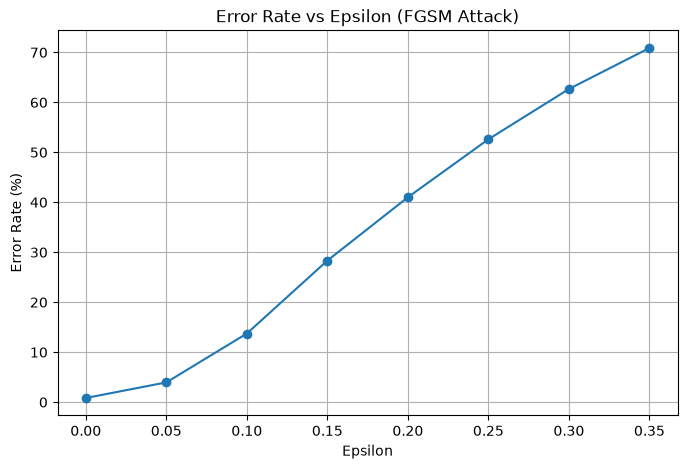

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    epsilons,
    error_rates,
    marker='o'
)

plt.xlabel("Epsilon")
plt.ylabel("Error Rate (%)")
plt.title("Error Rate vs Epsilon (FGSM Attack)")

plt.grid(True)
plt.show()

In [32]:
model_a.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_a(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

clean_accuracy = 100 * correct / total

print("Model A clean accuracy:", clean_accuracy, "%")

Model A clean accuracy: 99.17 %


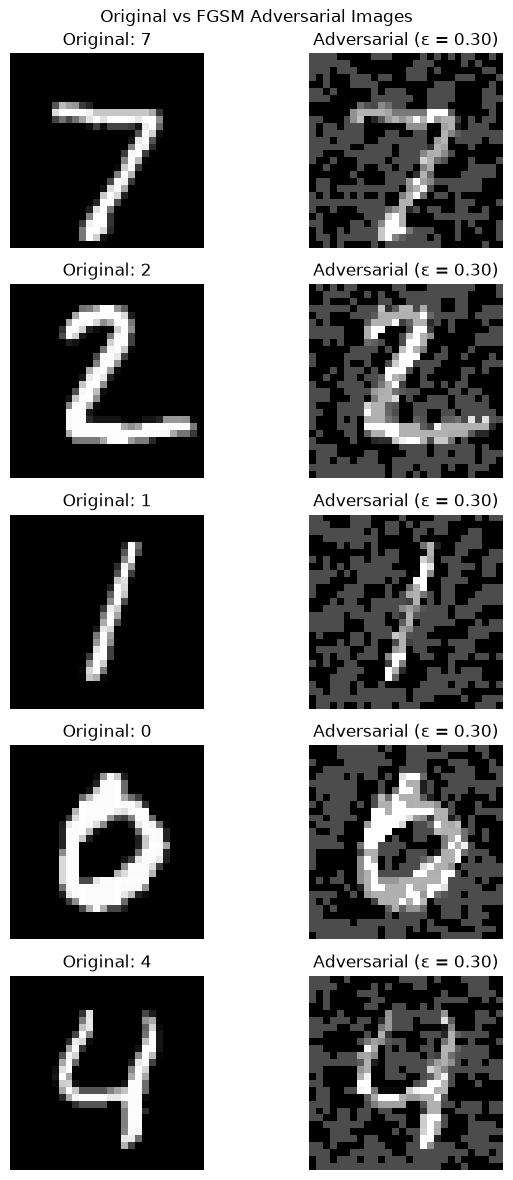

In [66]:
import matplotlib.pyplot as plt

# Select test images
images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

# Choose epsilon
epsilon = 0.30

# Generate adversarial images
model_a.eval()

adv_images = fgsm_attack(
    model_a,
    images,
    labels,
    epsilon
)

# Display 5 original and adversarial images
fig, axes = plt.subplots(5, 2, figsize=(7, 12))

for i in range(5):

    # Original image
    axes[i, 0].imshow(
        images[i].detach().cpu().squeeze(),
        cmap="gray"
    )
    axes[i, 0].set_title(
        "Original: " + str(labels[i].item())
    )
    axes[i, 0].axis("off")

    # Adversarial image
    axes[i, 1].imshow(
        adv_images[i].detach().cpu().squeeze(),
        cmap="gray"
    )
    axes[i, 1].set_title("Adversarial (ε = 0.30)")
    axes[i, 1].axis("off")

plt.suptitle("Original vs FGSM Adversarial Images")
plt.tight_layout()
plt.show()

part 3

In [80]:
# Create a completely new Model B
model_b = MNISTClassifier().to(device)

# Give Model B its own optimizer
optimizer_b = torch.optim.Adam(
    model_b.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

print("Model B created successfully!")

Model B created successfully!


In [81]:
epochs = 5

for epoch in range(epochs):

    model_b.train()

    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model_b(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Clear gradients
        optimizer_b.zero_grad()

        # Calculate gradients
        loss.backward()

        # Update Model B
        optimizer_b.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Model B - Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("Model B training completed!")

Model B - Epoch 1/5, Loss: 0.2500
Model B - Epoch 2/5, Loss: 0.0600
Model B - Epoch 3/5, Loss: 0.0420
Model B - Epoch 4/5, Loss: 0.0308
Model B - Epoch 5/5, Loss: 0.0246
Model B training completed!


In [82]:
model_b.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_b(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy_b = 100 * correct / total

print("Model B clean accuracy:", accuracy_b, "%")

Model B clean accuracy: 99.14 %


In [83]:
epsilon = 0.25

model_a.eval()

# Get test images
images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

# Generate adversarial images using Model A
adv_images = fgsm_attack(
    model_a,
    images,
    labels,
    epsilon
)

print("Adversarial images created using Model A!")

Adversarial images created using Model A!


In [84]:

model_a.eval()
model_b.eval()

correct = 0
total = 0

epsilon = 0.15

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Generate adversarial images using Model A
    adv_images = fgsm_attack(
        model_a,
        images,
        labels,
        epsilon
    )

    # Test the same images on Model B
    with torch.no_grad():
        outputs = model_b(adv_images)

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

transfer_accuracy = 100 * correct / total
transfer_error = 100 - transfer_accuracy

print("Total test images:", total)
print("Model B accuracy on Model A attacks:",
      transfer_accuracy, "%")
print("Transfer error rate:", transfer_error, "%")
print("Accuracy reduction:", accuracy_b - transfer_accuracy,
      "percentage points")

Total test images: 10000
Model B accuracy on Model A attacks: 85.58 %
Transfer error rate: 14.420000000000002 %
Accuracy reduction: 13.560000000000002 percentage points


In [85]:
print("TRANSFERABILITY RESULTS")
print("-------------------------------")

print("Model B clean accuracy:",
      accuracy_b, "%")

print("Model B accuracy on adversarial images:",
      transfer_accuracy, "%")

print("Accuracy reduction:",
      accuracy_b - transfer_accuracy, "%")

TRANSFERABILITY RESULTS
-------------------------------
Model B clean accuracy: 99.14 %
Model B accuracy on adversarial images: 85.58 %
Accuracy reduction: 13.560000000000002 %


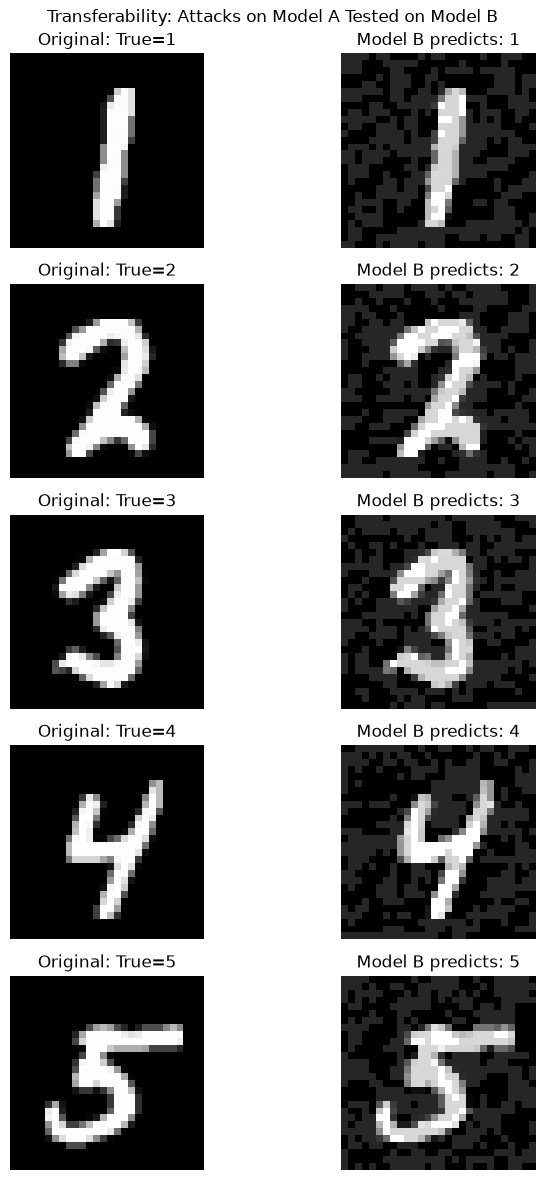

In [86]:
fig, axes = plt.subplots(5, 2, figsize=(8, 12))

for i in range(5):

    # Original image
    axes[i, 0].imshow(
        images[i].detach().cpu().squeeze(),
        cmap="gray"
    )

    axes[i, 0].set_title(
        f"Original: True={labels[i].item()}"
    )

    # Adversarial image created against A
    axes[i, 1].imshow(
        adv_images[i].detach().cpu().squeeze(),
        cmap="gray"
    )

    axes[i, 1].set_title(
        f"Model B predicts: {predictions[i].item()}"
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.suptitle("Transferability: Attacks on Model A Tested on Model B")
plt.tight_layout()
plt.show()

part 4

In [41]:
# Create a new model for adversarial training
model_adv = MNISTClassifier().to(device)

# Create a separate optimizer
optimizer_adv = torch.optim.Adam(
    model_adv.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

epsilon = 0.25

print("Adversarial model created successfully!")

Adversarial model created successfully!


In [42]:
epochs = 5

for epoch in range(epochs):

    model_adv.train()

    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Generate adversarial images using the current model
        adv_images = fgsm_attack(
            model_adv,
            images,
            labels,
            epsilon
        )

        # Predictions on normal images
        outputs_clean = model_adv(images)

        # Predictions on adversarial images
        outputs_adv = model_adv(adv_images)

        # Calculate both losses
        loss_clean = criterion(outputs_clean, labels)
        loss_adv = criterion(outputs_adv, labels)

        # Combine both losses
        loss = (loss_clean + loss_adv) / 2

        # Update model
        optimizer_adv.zero_grad()

        loss.backward()

        optimizer_adv.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("Adversarial training completed!")

Epoch 1/5, Loss: 0.6192
Epoch 2/5, Loss: 0.2220
Epoch 3/5, Loss: 0.1942
Epoch 4/5, Loss: 0.1048
Epoch 5/5, Loss: 0.0783
Adversarial training completed!


In [43]:

model_adv.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_adv(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

adv_clean_accuracy = 100 * correct / total

print(
    "Adversarial model clean accuracy:",
    adv_clean_accuracy,
    "%"
)

Adversarial model clean accuracy: 98.75 %


In [44]:
model_adv.eval()

correct = 0
total = 0

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Attack the adversarially trained model
    adv_images = fgsm_attack(
        model_adv,
        images,
        labels,
        epsilon
    )

    with torch.no_grad():

        outputs = model_adv(adv_images)

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

adv_accuracy = 100 * correct / total

print(
    "Adversarial model accuracy under FGSM attack:",
    adv_accuracy,
    "%"
)

Adversarial model accuracy under FGSM attack: 96.79 %


In [45]:
model_a.eval()

correct = 0
total = 0

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Attack Model A
    adv_images = fgsm_attack(
        model_a,
        images,
        labels,
        epsilon
    )

    with torch.no_grad():

        outputs = model_a(adv_images)

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

model_a_adv_accuracy = 100 * correct / total

print(
    "Original Model A adversarial accuracy:",
    model_a_adv_accuracy,
    "%"
)

Original Model A adversarial accuracy: 47.39 %


In [46]:
print("FINAL ADVERSARIAL TRAINING RESULTS")
print("===================================")

print("Model A clean accuracy: 99.17%")

print(
    "Model A adversarial accuracy:",
    model_a_adv_accuracy,
    "%"
)

print(
    "Model C clean accuracy:",
    adv_clean_accuracy,
    "%"
)

print(
    "Model C adversarial accuracy:",
    adv_accuracy,
    "%"
)

print("-----------------------------------")

print(
    "Robustness improvement:",
    adv_accuracy - model_a_adv_accuracy,
    "percentage points"
)

print(
    "Clean accuracy cost:",
    99.17 - adv_clean_accuracy,
    "percentage points"
)

FINAL ADVERSARIAL TRAINING RESULTS
Model A clean accuracy: 99.17%
Model A adversarial accuracy: 47.39 %
Model C clean accuracy: 98.75 %
Model C adversarial accuracy: 96.79 %
-----------------------------------
Robustness improvement: 49.400000000000006 percentage points
Clean accuracy cost: 0.4200000000000017 percentage points
